In [2]:
import numpy as np

In [3]:
def get_n_primes(n):
    assert n >= 1, "n must be at least 1"
    i = 2
    lst = [2]
    while len(lst) < n:
        if any([i % p == 0 for p in lst]):
            i += 1
        else:
            lst.append(i)
    return np.array(lst)

In [4]:
N = 10000
primes = get_n_primes(N)
primes

array([     2,      3,      5, ..., 104717, 104723, 104729])

In [5]:
primes_mod_2d = np.array([[j % i if j > i else 0 for j in primes] for i in primes])

In [6]:
primes_mod_2d

array([[ 0,  1,  1, ...,  1,  1,  1],
       [ 0,  0,  2, ...,  2,  2,  2],
       [ 0,  0,  0, ...,  2,  3,  4],
       ...,
       [ 0,  0,  0, ...,  0,  6, 12],
       [ 0,  0,  0, ...,  0,  0,  6],
       [ 0,  0,  0, ...,  0,  0,  0]])

In [7]:
row_sums = np.sum(primes_mod_2d, axis=1)
col_sums = np.sum(primes_mod_2d, axis=0)
print(row_sums)
print(col_sums)

[ 9999 15008 25006 ...    18     6     0]
[        0         1         3 ... 178843557 178849741 178849237]


In [8]:
row_sums + col_sums

array([     9999,     15009,     25009, ..., 178843575, 178849747,
       178849237])

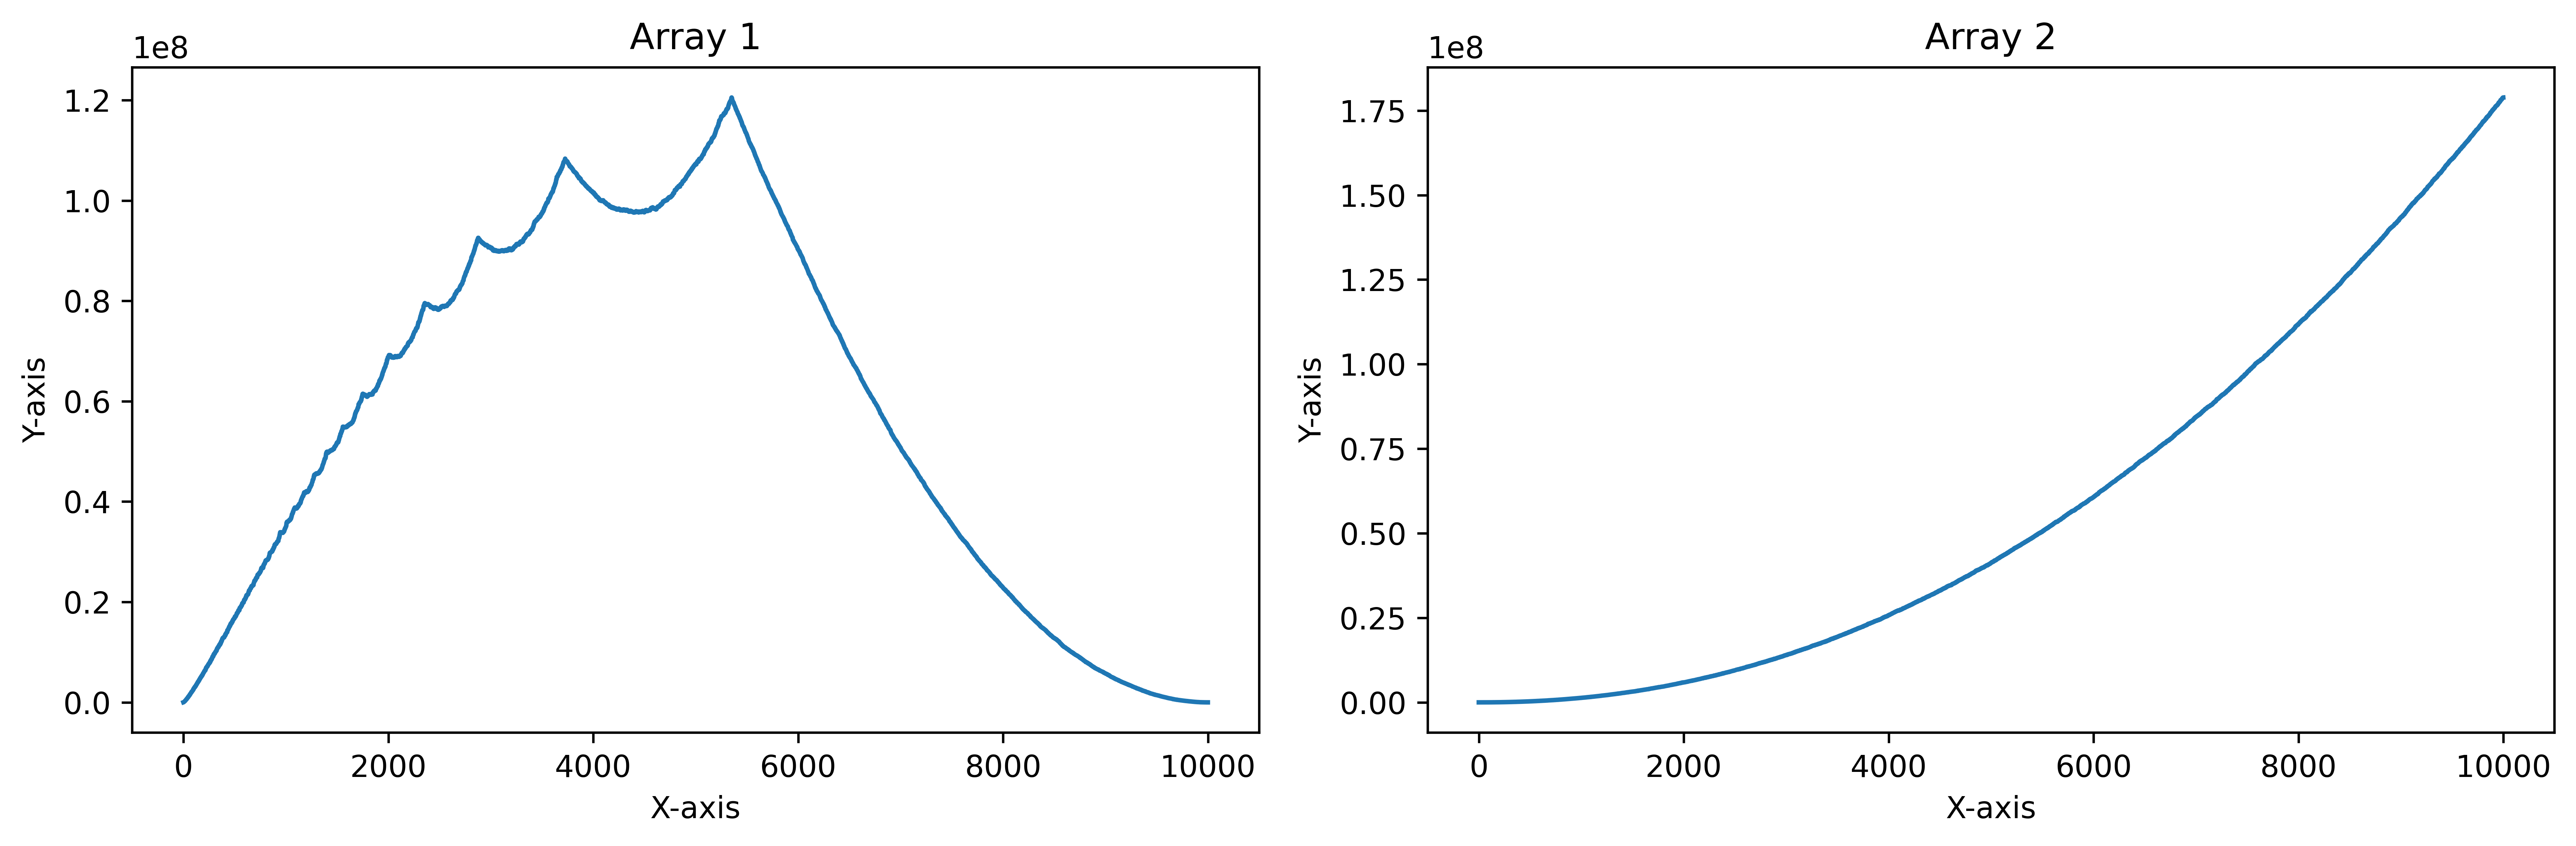

In [15]:
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Plot the first array on the left subplot
axs[0].plot(row_sums)
axs[0].set_title('Array 1')
axs[0].set_xlabel('X-axis')
axs[0].set_ylabel('Y-axis')

# Plot the second array on the right subplot
axs[1].plot(col_sums)
axs[1].set_title('Array 2')
axs[1].set_xlabel('X-axis')
axs[1].set_ylabel('Y-axis')

# Layout so plots do not overlap
fig.tight_layout()

plt.show()

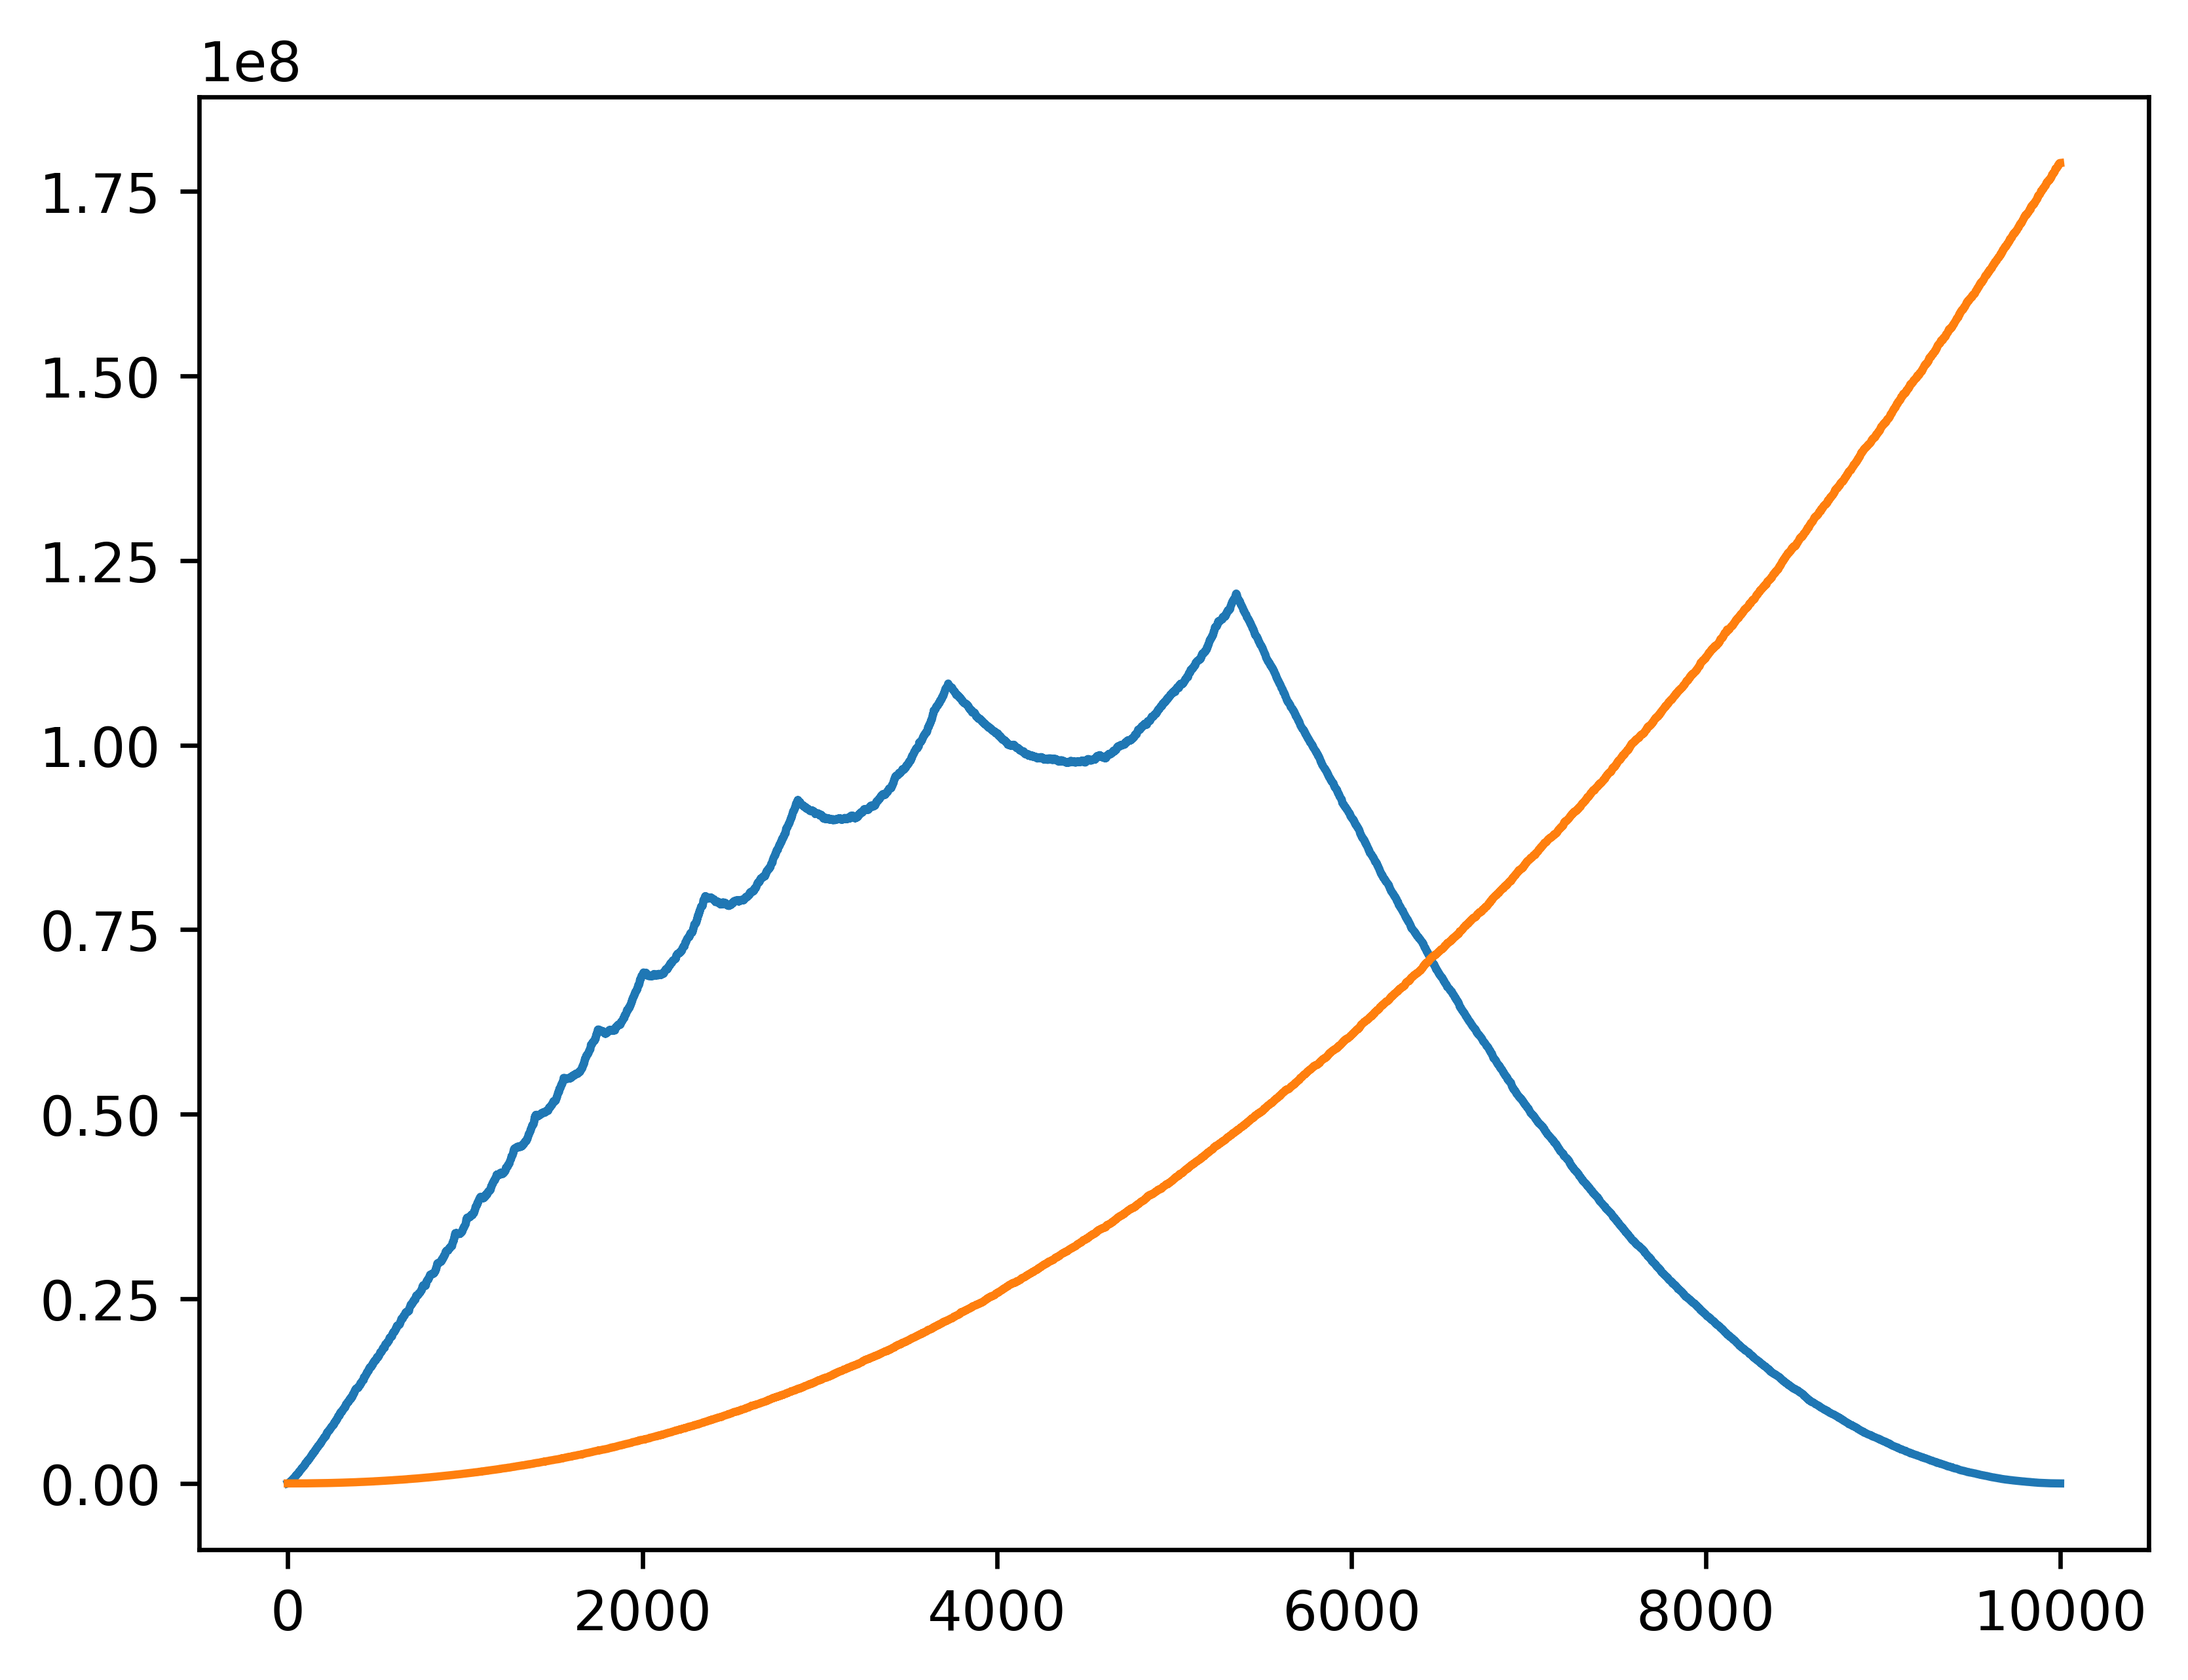

In [16]:
plt.plot(row_sums)
plt.plot(col_sums)
plt.savefig(f"./output/img_{str(N).zfill(5)}.png")

6448


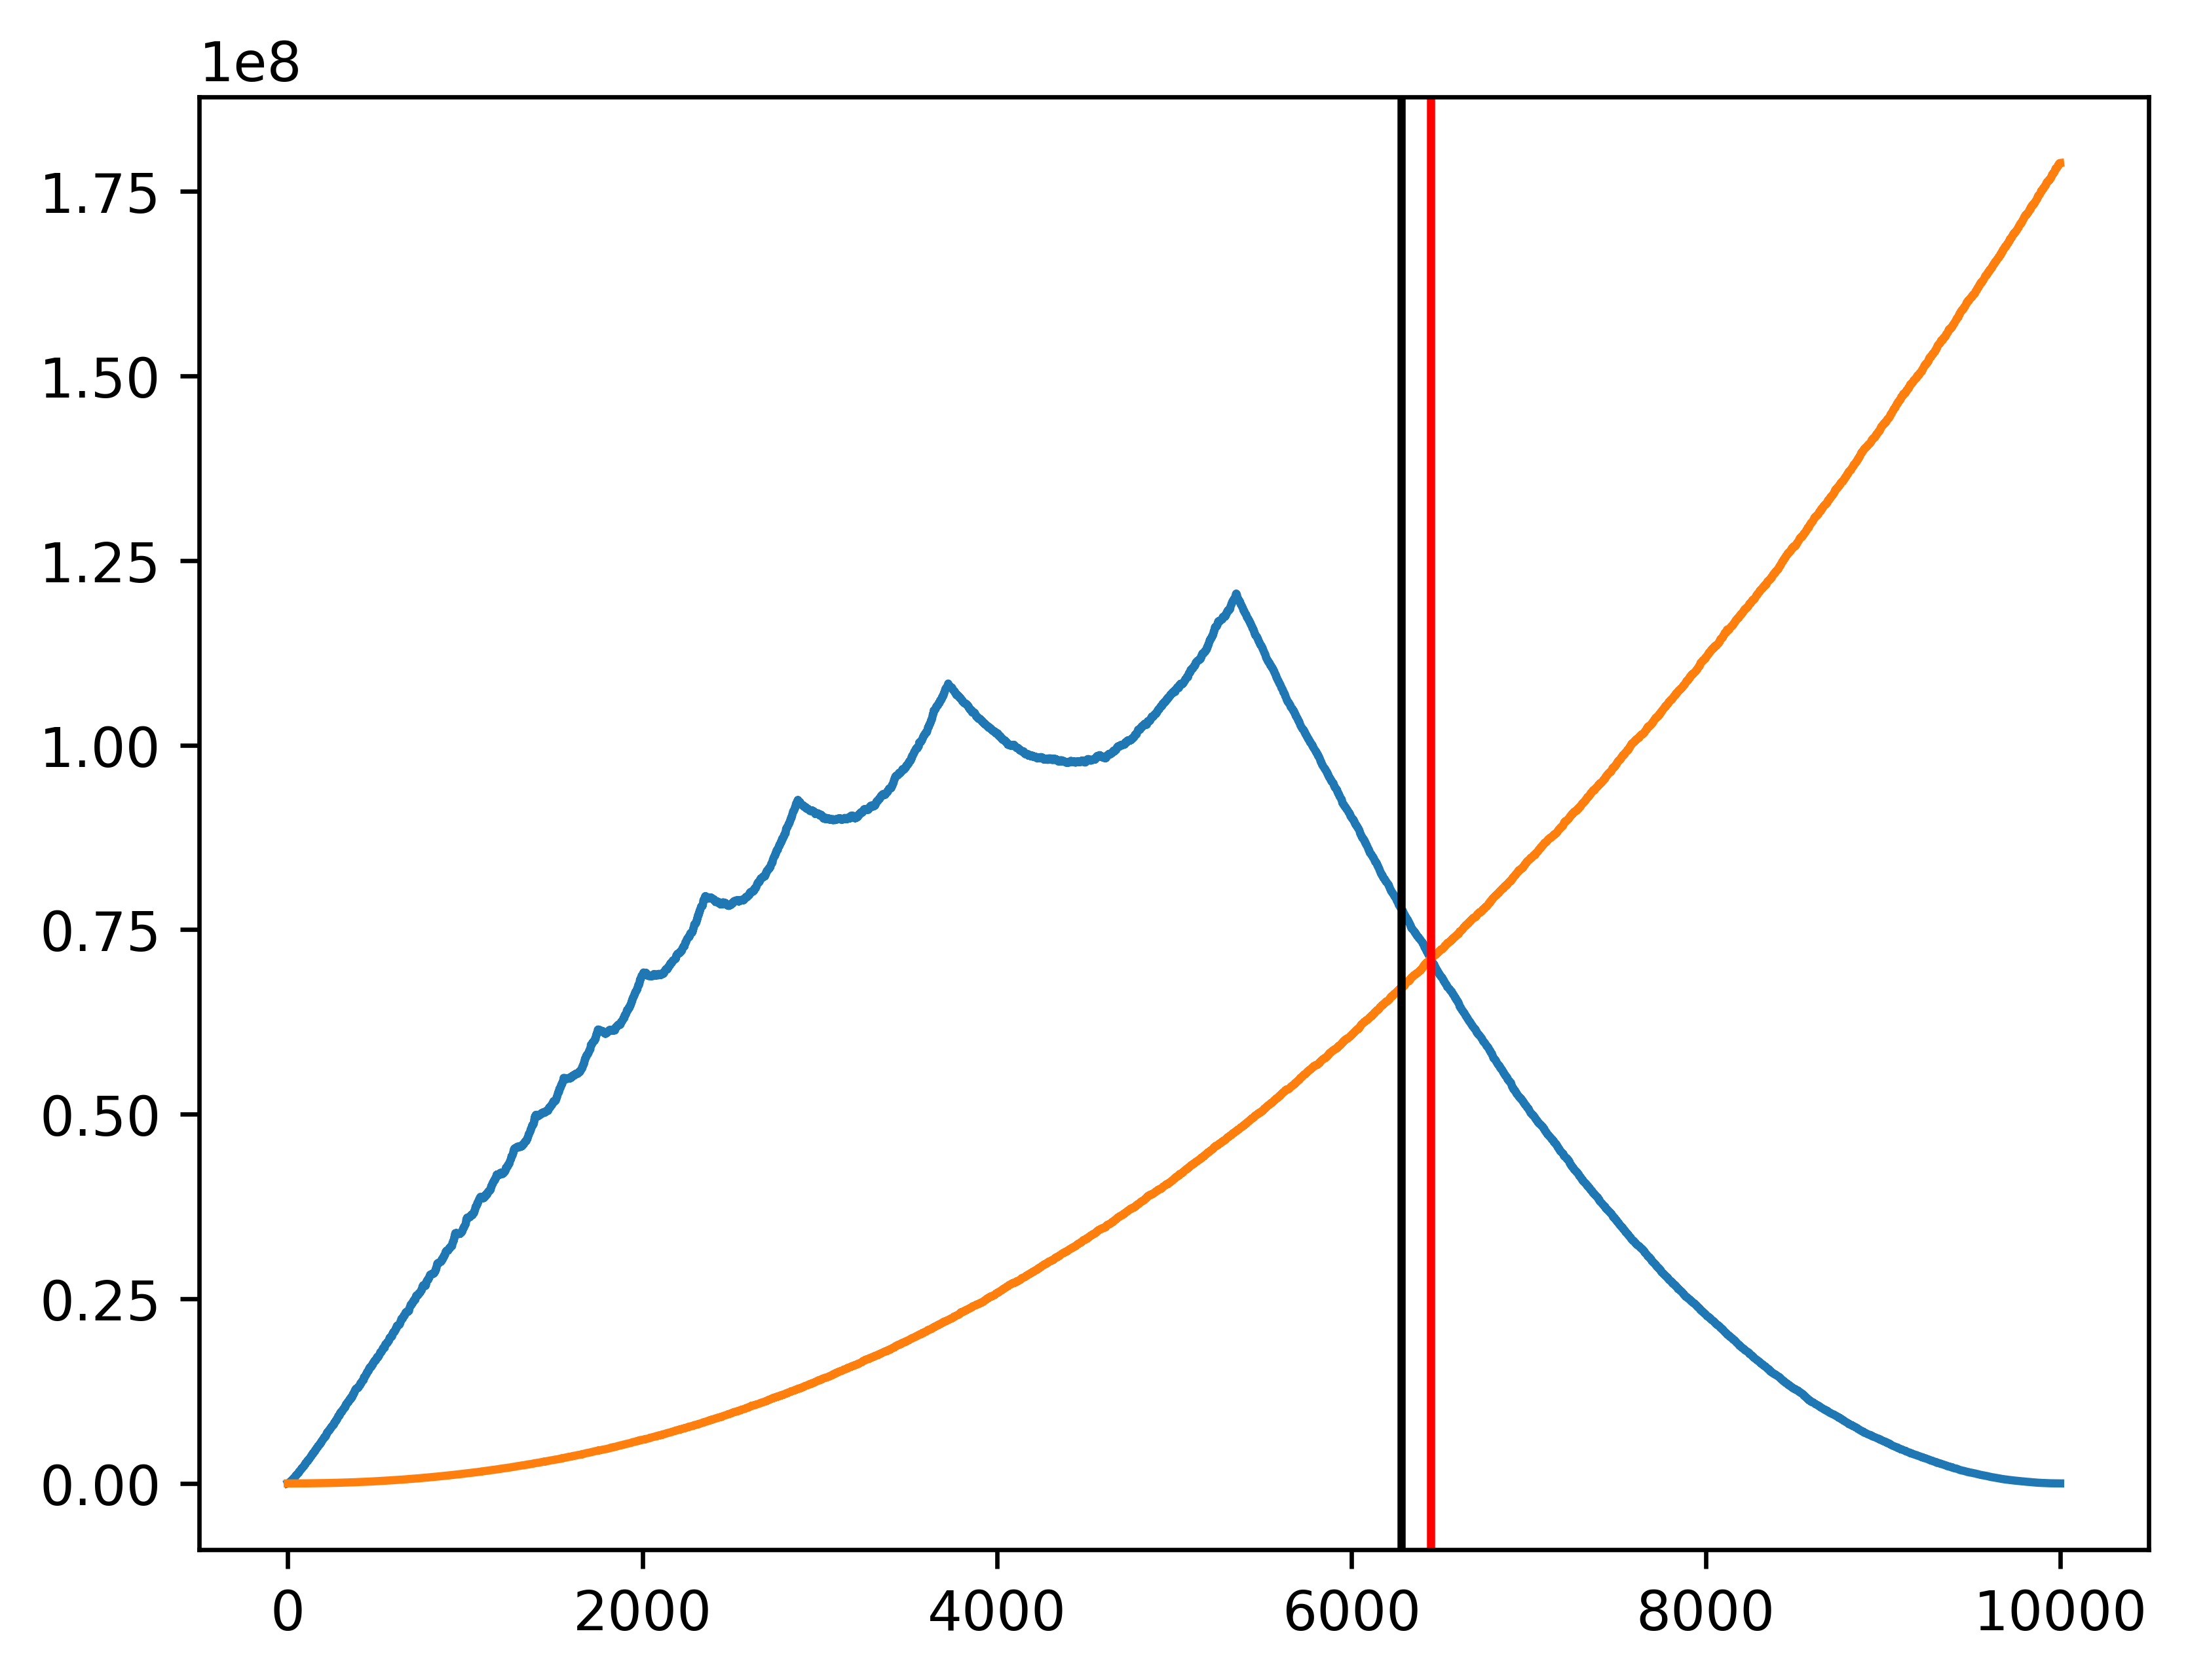

In [24]:
import math


def find_surpass_index(col_sums, row_sums):
    for i in range(len(col_sums)):
        if col_sums[i] > row_sums[i]:
            return i
    return -1


plt.plot(row_sums)
plt.plot(col_sums)
plt.axvline(x=N / 10 * 2 * math.pi, color="black", linestyle="-")

idx = find_surpass_index(col_sums, row_sums)
print(idx)

plt.axvline(x=idx, color="red", linestyle="-")

/var/folders/pj/bkfm1sd12ps6vx6kl__yl24w0000gn/T/ipykernel_29697/3077146457.py:1: RuntimeWarning: divide by zero encountered in log
  log_sum = np.log(col_sums)


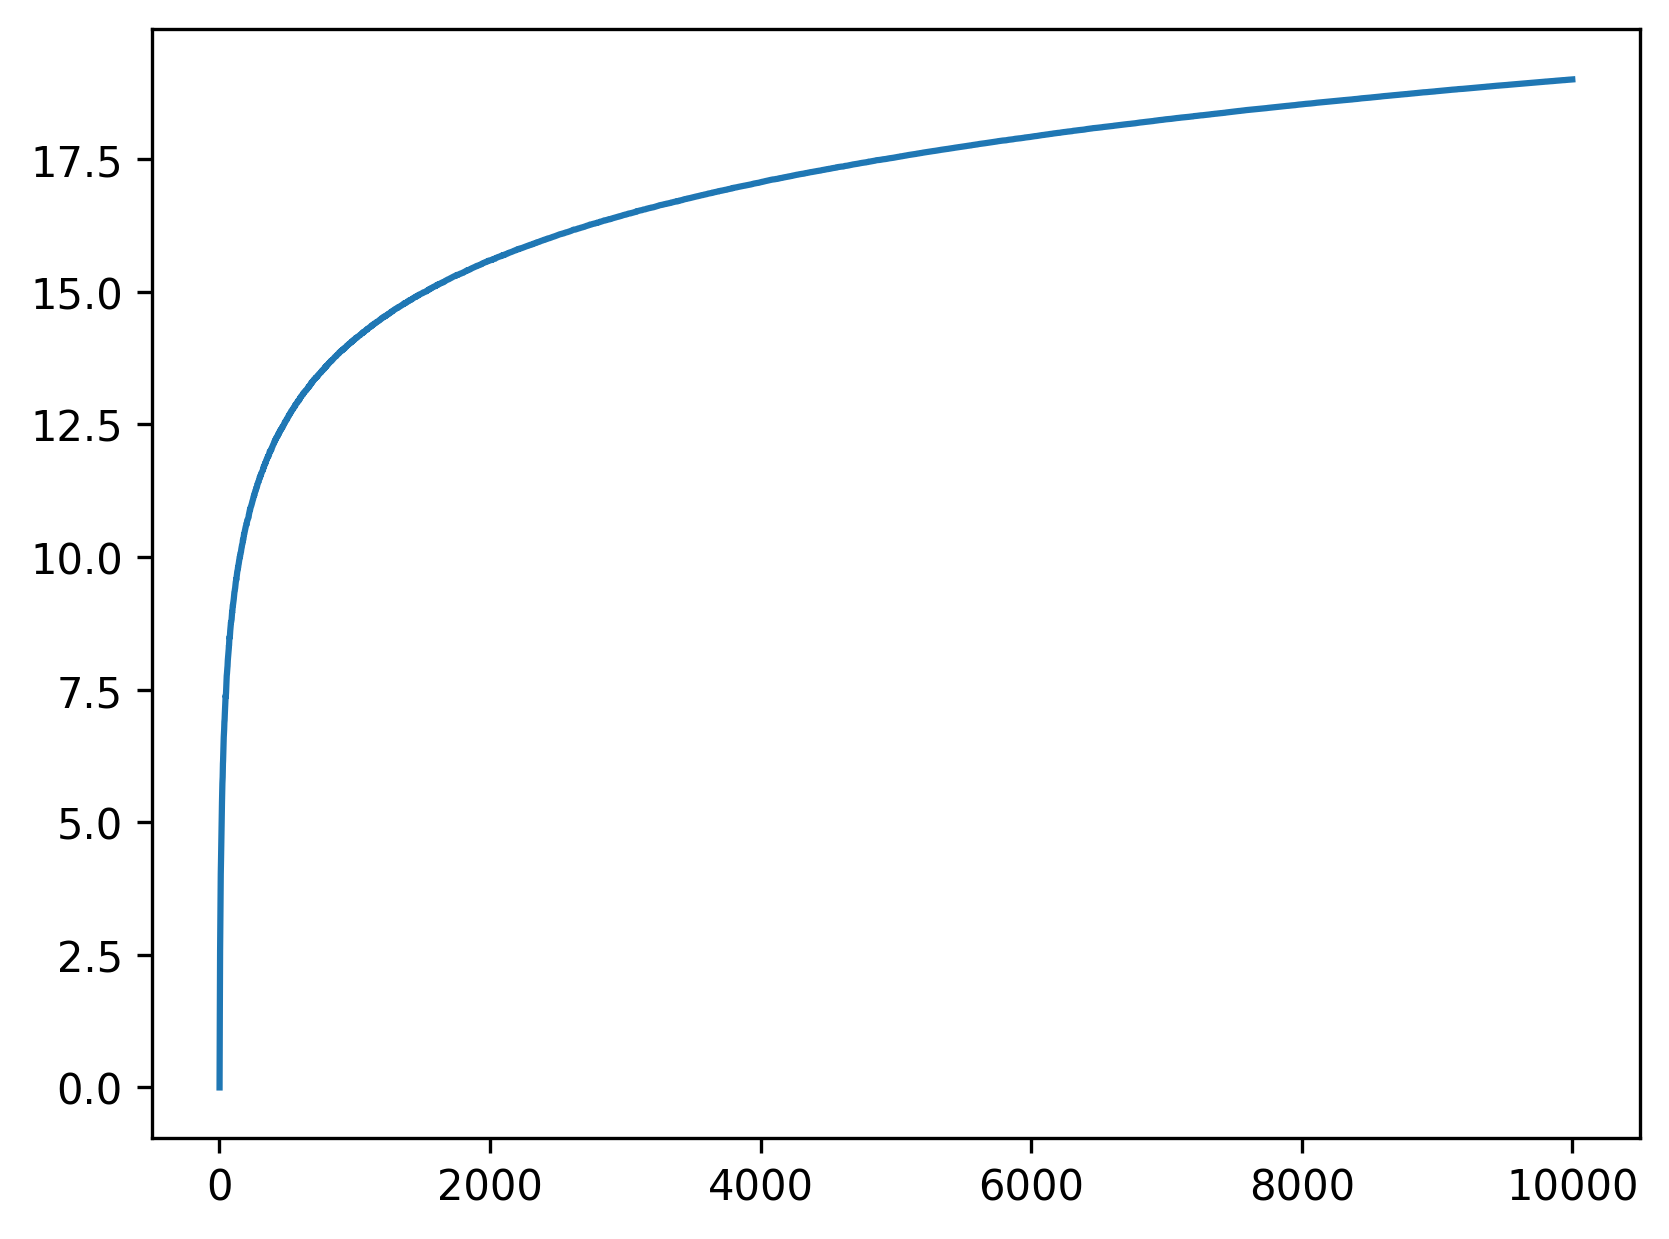

In [12]:
log_sum = np.log(col_sums)
plt.plot(log_sum)